In [1]:
!pip install photutils

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /usr/share/pip-wheels


In [75]:
import numpy as np
import astropy.io
from astropy.io import fits
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import math
import os
import glob
%matplotlib inline
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

In [3]:
bias1 = 'bias1.fit'
bias2 = 'bias2.fit'
bias3 = 'bias3.fit'

bias1_header = fits.getheader(bias1)
bias1_data = fits.getdata(bias1)

In [4]:
bias1_header

SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 1608 /fastest changing axis                           
NAXIS2  =                 1104 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2026-02-05T03:29:26.78' /YYYY-MM-DDThh:mm:ss observation, UT         
EXPTIME =   3.415488390601E-05 /Exposure time in seconds                        
EXPOSURE=   3.415488390601E-05 /Exposure time in seconds                        
SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   
CCD-TEMP=  -20.020000457763672 /CCD temperature at start of exposure in C       
XPIXSZ  =   9.00000000000000

In [5]:
bias1_data

array([[240, 241, 241, ..., 241, 240, 241],
       [241, 241, 241, ..., 240, 240, 241],
       [241, 241, 241, ..., 241, 241, 241],
       ...,
       [240, 241, 241, ..., 240, 241, 241],
       [240, 241, 240, ..., 241, 241, 240],
       [240, 240, 241, ..., 242, 241, 241]], dtype=uint16)

In [6]:
bias1_header['EGAIN']
#photoelectrons per ADU?

11.183819770812988

In [7]:
bias2_header = fits.getheader(bias2)
bias2_data = fits.getdata(bias2)
bias3_header = fits.getheader(bias3)
bias3_data = fits.getdata(bias3)

In [8]:
hdul = fits.open(bias1)
bias = [bias1_data, bias2_data, bias3_data]
bias

[array([[240, 241, 241, ..., 241, 240, 241],
        [241, 241, 241, ..., 240, 240, 241],
        [241, 241, 241, ..., 241, 241, 241],
        ...,
        [240, 241, 241, ..., 240, 241, 241],
        [240, 241, 240, ..., 241, 241, 240],
        [240, 240, 241, ..., 242, 241, 241]], dtype=uint16),
 array([[240, 241, 241, ..., 241, 240, 241],
        [240, 241, 240, ..., 241, 241, 239],
        [240, 240, 241, ..., 241, 241, 241],
        ...,
        [241, 240, 240, ..., 240, 241, 241],
        [242, 241, 241, ..., 241, 241, 240],
        [241, 240, 241, ..., 242, 240, 240]], dtype=uint16),
 array([[240, 240, 240, ..., 241, 239, 240],
        [240, 241, 241, ..., 241, 241, 240],
        [242, 241, 241, ..., 241, 241, 240],
        ...,
        [240, 241, 240, ..., 241, 241, 240],
        [240, 241, 241, ..., 240, 240, 241],
        [240, 241, 240, ..., 241, 240, 240]], dtype=uint16)]

In [9]:
len(bias)

3

In [10]:
masterbias = np.mean(np.asarray(bias), axis=0)
masterbias

array([[240.        , 240.66666667, 240.66666667, ..., 241.        ,
        239.66666667, 240.66666667],
       [240.33333333, 241.        , 240.66666667, ..., 240.66666667,
        240.66666667, 240.        ],
       [241.        , 240.66666667, 241.        , ..., 241.        ,
        241.        , 240.66666667],
       ...,
       [240.33333333, 240.66666667, 240.33333333, ..., 240.33333333,
        241.        , 240.66666667],
       [240.66666667, 241.        , 240.66666667, ..., 240.66666667,
        240.66666667, 240.33333333],
       [240.33333333, 240.33333333, 240.66666667, ..., 241.66666667,
        240.33333333, 240.33333333]])

In [52]:
write = fits.PrimaryHDU(masterbias)
write.writeto('masterbias.fit')

In [11]:
dark1 = 'dark4_s.fit'
dark2 = 'dark4_s2.fit'
dark3 = 'dark4_s3.fit'

dark1_header = fits.getheader(dark1)
dark1_data = fits.getdata(dark1)
dark2_header = fits.getheader(dark2)
dark2_data = fits.getdata(dark2)
dark3_header = fits.getheader(dark3)
dark3_data = fits.getdata(dark3)

In [12]:
dark = [dark1_data, dark2_data, dark3_data]
dark

[array([[240, 241, 241, ..., 241, 240, 241],
        [241, 241, 241, ..., 241, 241, 241],
        [240, 242, 242, ..., 239, 240, 240],
        ...,
        [241, 240, 241, ..., 240, 242, 243],
        [240, 241, 241, ..., 241, 240, 242],
        [241, 241, 242, ..., 241, 242, 241]], dtype=uint16),
 array([[241, 241, 239, ..., 241, 242, 241],
        [241, 241, 241, ..., 241, 243, 240],
        [241, 242, 241, ..., 240, 240, 241],
        ...,
        [242, 241, 241, ..., 241, 242, 241],
        [241, 241, 240, ..., 241, 241, 242],
        [241, 240, 240, ..., 241, 242, 241]], dtype=uint16),
 array([[240, 240, 240, ..., 241, 242, 241],
        [240, 241, 240, ..., 242, 241, 240],
        [240, 242, 240, ..., 242, 242, 240],
        ...,
        [241, 241, 240, ..., 241, 242, 242],
        [242, 240, 242, ..., 242, 241, 241],
        [240, 240, 240, ..., 241, 241, 242]], dtype=uint16)]

In [13]:
len(dark)

3

In [14]:
masterdark = np.mean(np.asarray(dark), axis=0)
masterdark
#Okay nevermind don't use darks

array([[240.33333333, 240.66666667, 240.        , ..., 241.        ,
        241.33333333, 241.        ],
       [240.66666667, 241.        , 240.66666667, ..., 241.33333333,
        241.66666667, 240.33333333],
       [240.33333333, 242.        , 241.        , ..., 240.33333333,
        240.66666667, 240.33333333],
       ...,
       [241.33333333, 240.66666667, 240.66666667, ..., 240.66666667,
        242.        , 242.        ],
       [241.        , 240.66666667, 241.        , ..., 241.33333333,
        240.66666667, 241.66666667],
       [240.66666667, 240.33333333, 240.66666667, ..., 241.        ,
        241.66666667, 241.33333333]])

In [15]:
RUCAM1 = 'Vband RuCAM 4_s.fit'
RUCAM2 = 'Vband RuCAM 4_s2.fit'
RUCAM3 = 'Vband RuCAM 4_s3.fit'

In [16]:
RUCAM1_header = fits.getheader(RUCAM1)
RUCAM1_data = fits.getdata(RUCAM1)
RUCAM2_header = fits.getheader(RUCAM2)
RUCAM2_data = fits.getdata(RUCAM2)
RUCAM3_header = fits.getheader(RUCAM3)
RUCAM3_data = fits.getdata(RUCAM3)

In [17]:
RUCAM1_header

SIMPLE  =                    T                                                  
BITPIX  =                   16 /8 unsigned int, 16 & 32 int, -32 & -64 real     
NAXIS   =                    2 /number of axes                                  
NAXIS1  =                 1608 /fastest changing axis                           
NAXIS2  =                 1104 /next to fastest changing axis                   
BSCALE  =   1.0000000000000000 /physical = BZERO + BSCALE*array_value           
BZERO   =   32768.000000000000 /physical = BZERO + BSCALE*array_value           
DATE-OBS= '2026-02-05T03:27:08.02' /YYYY-MM-DDThh:mm:ss observation, UT         
EXPTIME =   3.9999978542327881 /Exposure time in seconds                        
EXPOSURE=   3.9999978542327881 /Exposure time in seconds                        
SET-TEMP=  -20.000000000000000 /CCD temperature setpoint in C                   
CCD-TEMP=  -19.989999771118164 /CCD temperature at start of exposure in C       
XPIXSZ  =   9.00000000000000

In [18]:
RUCAM = [RUCAM1_data, RUCAM2_data, RUCAM3_data]
RUCAM

[array([[244, 244, 245, ..., 243, 245, 244],
        [244, 243, 246, ..., 246, 243, 244],
        [245, 244, 244, ..., 244, 245, 243],
        ...,
        [245, 243, 244, ..., 244, 246, 243],
        [245, 245, 245, ..., 244, 245, 245],
        [243, 244, 246, ..., 243, 246, 245]], dtype=uint16),
 array([[242, 245, 244, ..., 243, 245, 244],
        [245, 242, 246, ..., 246, 244, 244],
        [244, 244, 243, ..., 244, 244, 243],
        ...,
        [244, 245, 244, ..., 246, 245, 244],
        [245, 246, 245, ..., 245, 245, 246],
        [245, 244, 245, ..., 245, 245, 245]], dtype=uint16),
 array([[243, 244, 245, ..., 243, 244, 245],
        [245, 244, 244, ..., 243, 244, 244],
        [244, 244, 243, ..., 244, 245, 243],
        ...,
        [244, 242, 244, ..., 245, 244, 244],
        [243, 246, 243, ..., 245, 245, 244],
        [243, 244, 244, ..., 245, 245, 246]], dtype=uint16)]

In [19]:
masterRUCAM = np.mean(np.asarray(RUCAM), axis=0)
masterRUCAM

array([[243.        , 244.33333333, 244.66666667, ..., 243.        ,
        244.66666667, 244.33333333],
       [244.66666667, 243.        , 245.33333333, ..., 245.        ,
        243.66666667, 244.        ],
       [244.33333333, 244.        , 243.33333333, ..., 244.        ,
        244.66666667, 243.        ],
       ...,
       [244.33333333, 243.33333333, 244.        , ..., 245.        ,
        245.        , 243.66666667],
       [244.33333333, 245.66666667, 244.33333333, ..., 244.66666667,
        245.        , 245.        ],
       [243.66666667, 244.        , 245.        , ..., 244.33333333,
        245.33333333, 245.33333333]])

In [17]:
write = fits.PrimaryHDU(masterdark)
write.writeto('masterdark.fit')

write = fits.PrimaryHDU(masterRUCAM)
write.writeto('masterRUCAM.fit')
#DON'T RERUN CELL

In [20]:
corrected1_RUCAM = (masterRUCAM - masterbias) / masterdark

In [21]:
corrected1_RUCAM


array([[0.01248266, 0.01523546, 0.01666667, ..., 0.00829876, 0.02071823,
        0.01521438],
       [0.01800554, 0.00829876, 0.01939058, ..., 0.0179558 , 0.01241379,
        0.01664355],
       [0.01386963, 0.0137741 , 0.00968188, ..., 0.01248266, 0.01523546,
        0.00970874],
       ...,
       [0.01657459, 0.01108033, 0.01523546, ..., 0.01939058, 0.01652893,
        0.01239669],
       [0.01521438, 0.01939058, 0.01521438, ..., 0.01657459, 0.01800554,
        0.01931034],
       [0.01385042, 0.01525659, 0.01800554, ..., 0.01106501, 0.02068966,
        0.02071823]])

In [22]:
flats1 = 'flats4s.fit'
flats2 = '2flats4s.fit'
flats3 = '3flats4s.fit'

flats1_header = fits.getheader(flats1)
flats1_data = fits.getdata(flats1)
flats2_header = fits.getheader(flats2)
flats2_data = fits.getdata(flats2)
flats3_header = fits.getheader(flats3)
flats3_data = fits.getdata(flats3)

In [23]:
flats = [flats1_data, flats2_data, flats3_data]
flats

[array([[1741, 1737, 1730, ..., 1776, 1768, 1768],
        [1720, 1723, 1752, ..., 1790, 1781, 1757],
        [1751, 1741, 1720, ..., 1760, 1793, 1783],
        ...,
        [1724, 1726, 1725, ..., 1749, 1775, 1760],
        [1737, 1711, 1728, ..., 1756, 1772, 1763],
        [1719, 1730, 1724, ..., 1767, 1766, 1756]], dtype=uint16),
 array([[1682, 1710, 1697, ..., 1726, 1750, 1719],
        [1730, 1689, 1699, ..., 1736, 1748, 1740],
        [1714, 1690, 1695, ..., 1715, 1738, 1735],
        ...,
        [1688, 1696, 1699, ..., 1722, 1714, 1715],
        [1681, 1679, 1673, ..., 1726, 1725, 1711],
        [1676, 1677, 1693, ..., 1728, 1743, 1737]], dtype=uint16),
 array([[1671, 1687, 1681, ..., 1715, 1722, 1722],
        [1693, 1664, 1678, ..., 1718, 1720, 1724],
        [1687, 1669, 1684, ..., 1705, 1725, 1719],
        ...,
        [1668, 1662, 1668, ..., 1733, 1721, 1712],
        [1679, 1685, 1682, ..., 1719, 1708, 1703],
        [1655, 1681, 1673, ..., 1697, 1712, 1709]], dtype=uint

In [24]:
masterflats = np.mean(np.asarray(flats), axis=0)
masterflats


array([[1698.        , 1711.33333333, 1702.66666667, ..., 1739.        ,
        1746.66666667, 1736.33333333],
       [1714.33333333, 1692.        , 1709.66666667, ..., 1748.        ,
        1749.66666667, 1740.33333333],
       [1717.33333333, 1700.        , 1699.66666667, ..., 1726.66666667,
        1752.        , 1745.66666667],
       ...,
       [1693.33333333, 1694.66666667, 1697.33333333, ..., 1734.66666667,
        1736.66666667, 1729.        ],
       [1699.        , 1691.66666667, 1694.33333333, ..., 1733.66666667,
        1735.        , 1725.66666667],
       [1683.33333333, 1696.        , 1696.66666667, ..., 1730.66666667,
        1740.33333333, 1734.        ]])

In [30]:
write = fits.PrimaryHDU(masterflats)
write.writeto('masterflats.fit')

In [26]:
REALcorrected_RUCAM = (masterRUCAM - masterbias) / (masterflats - masterbias)

In [27]:
REALcorrected_RUCAM

array([[0.00205761, 0.0024932 , 0.00273598, ..., 0.00133511, 0.00331785,
        0.00245153],
       [0.00293985, 0.00137836, 0.00317676, ..., 0.00287483, 0.00198807,
        0.00266607],
       [0.00225785, 0.00228415, 0.00159963, ..., 0.0020193 , 0.00242665,
        0.00155039],
       ...,
       [0.00275292, 0.00183402, 0.00251659, ..., 0.00312291, 0.00267439,
        0.00201568],
       [0.00251429, 0.00321691, 0.00252236, ..., 0.00267917, 0.00289984,
        0.00314183],
       [0.00231   , 0.00251889, 0.00297619, ..., 0.00179091, 0.00333333,
        0.00334747]])

In [34]:
write = fits.PrimaryHDU(REALcorrected_RUCAM)
write.writeto('REALcorrected_RUCAM.fit')

In [28]:
print(REALcorrected_RUCAM.shape)

(1104, 1608)


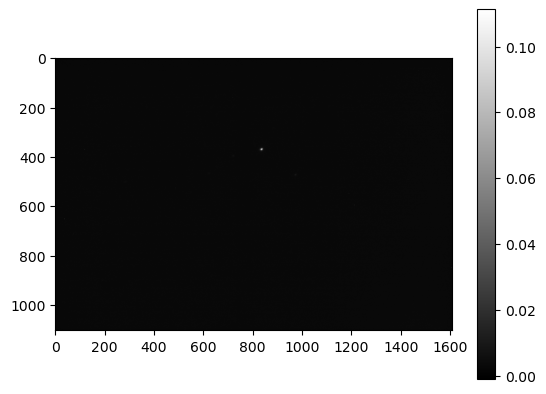

In [206]:
plt.imshow(REALcorrected_RUCAM, cmap="gray")
plt.colorbar()
plt.savefig('corrected_RUCAM.png')

In [30]:
print("Min:", np.min(REALcorrected_RUCAM))
print("Max:", np.max(REALcorrected_RUCAM))
print("Mean:", np.mean(REALcorrected_RUCAM))
print("Stdev:", np.std(REALcorrected_RUCAM))

Min: -0.0010841283607979123
Max: 0.1113256113256113
Mean: 0.0027959909242144215
Stdev: 0.0006293786274386098


In [180]:
positions = [(837, 373)]
aperture = CircularAperture(positions, r=12.0)
annulus = CircularAnnulus(positions, r_in=15, r_out=25)

In [70]:
from photutils.datasets import make_wcs
from astropy.wcs import WCS
wcs = make_wcs((100, 100))
sky_aperture = aperture.to_sky(wcs)
sky_aperture
#REALcorrected_RUCAM
#flats2_data = fits.getdata(flats2)

<SkyCircularAperture(<SkyCoord (ICRS): (ra, dec) in deg
    [(197.88934892, -1.34209923)]>, r=1.4999997433397259 arcsec)>

In [181]:
from photutils.aperture import aperture_photometry
image = aperture_photometry(REALcorrected_RUCAM, aperture)
background = aperture_photometry(REALcorrected_RUCAM, annulus)

In [182]:
background_mean = background['aperture_sum'][0] / annulus.area

In [183]:

net_counts = image['aperture_sum'][0] - background_mean * aperture.area
net_counts
# COunts for RUCAM???

5.763715665127074

In [192]:
counts_sec = net_counts/4 #exposure time in s
counts_sec

1.4409289162817684

In [81]:
#standard star
standard1 = 'standard.01.1.fit'
standard2 = 'standard.01.2.fit'
standard3 = 'standard.01.3.fit'

standard1_header = fits.getheader(standard1)
standard1_data = fits.getdata(standard1)
standard2_header = fits.getheader(standard2)
standard2_data = fits.getdata(standard2)
standard3_header = fits.getheader(standard3)
standard3_data = fits.getdata(standard3)

In [82]:
standard = [standard1_data, standard2_data, standard3_data]
standard
            

[array([[240, 242, 242, ..., 241, 241, 241],
        [241, 240, 241, ..., 240, 240, 241],
        [241, 240, 241, ..., 241, 241, 241],
        ...,
        [241, 240, 241, ..., 239, 241, 241],
        [242, 240, 241, ..., 241, 240, 241],
        [241, 240, 240, ..., 241, 239, 240]], dtype=uint16),
 array([[241, 241, 240, ..., 242, 241, 240],
        [241, 242, 241, ..., 241, 240, 241],
        [242, 241, 242, ..., 241, 240, 240],
        ...,
        [241, 241, 240, ..., 240, 241, 241],
        [240, 242, 242, ..., 239, 240, 242],
        [240, 240, 242, ..., 241, 242, 242]], dtype=uint16),
 array([[240, 241, 240, ..., 240, 241, 241],
        [241, 240, 241, ..., 240, 241, 241],
        [241, 241, 241, ..., 240, 241, 241],
        ...,
        [240, 240, 241, ..., 240, 240, 241],
        [242, 241, 241, ..., 240, 241, 242],
        [242, 241, 240, ..., 241, 241, 242]], dtype=uint16)]

In [83]:
masterstandard = np.mean(np.asarray(standard), axis=0)
masterstandard

array([[240.33333333, 241.33333333, 240.66666667, ..., 241.        ,
        241.        , 240.66666667],
       [241.        , 240.66666667, 241.        , ..., 240.33333333,
        240.33333333, 241.        ],
       [241.33333333, 240.66666667, 241.33333333, ..., 240.66666667,
        240.66666667, 240.66666667],
       ...,
       [240.66666667, 240.33333333, 240.66666667, ..., 239.66666667,
        240.66666667, 241.        ],
       [241.33333333, 241.        , 241.33333333, ..., 240.        ,
        240.33333333, 241.66666667],
       [241.        , 240.33333333, 240.66666667, ..., 241.        ,
        240.66666667, 241.33333333]])

In [84]:
write = fits.PrimaryHDU(masterstandard)
write.writeto('masterstandard.fit')
#forgot to correct don't use this

In [85]:
corrected_standard = (masterstandard - masterbias) / (masterflats - masterbias)
corrected_standard

array([[ 0.00022862,  0.00045331,  0.        , ...,  0.        ,
         0.00088476,  0.        ],
       [ 0.00045228, -0.00022973,  0.00022691, ..., -0.00022114,
        -0.0002209 ,  0.00066652],
       [ 0.00022578,  0.        ,  0.00022852, ..., -0.00022437,
        -0.0002206 ,  0.        ],
       ...,
       [ 0.00022941, -0.00022925,  0.00022878, ..., -0.00044613,
        -0.00022287,  0.00022396],
       [ 0.00045714,  0.        ,  0.00045861, ..., -0.00044653,
        -0.00022306,  0.00089767],
       [ 0.000462  ,  0.        ,  0.        , ..., -0.00044773,
         0.00022222,  0.00066949]])

In [86]:
write = fits.PrimaryHDU(corrected_standard)
write.writeto('corrected_standard.fit')

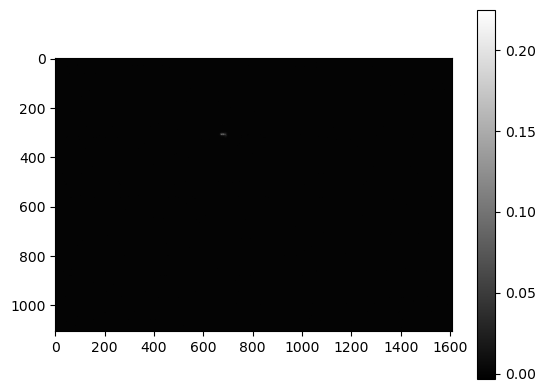

In [205]:
plt.imshow(corrected_standard, cmap="gray")
plt.colorbar()
#681, 309 on DS9
plt.savefig('corrected_standard.png')

In [173]:
positions_standard = [(681, 309)]
aperture_standard = CircularAperture(positions_standard, r=10.0)
annulus_standard = CircularAnnulus(positions_standard, r_in=18, r_out=30)

In [92]:
wcs = make_wcs((100, 100))
sky_aperture_standard = aperture_standard.to_sky(wcs)
sky_aperture_standard

<SkyCircularAperture(<SkyCoord (ICRS): (ra, dec) in deg
    [(197.88997615, -1.34674089)]>, r=1.4999998344048404 arcsec)>

In [185]:
image_standard = aperture_photometry(corrected_standard, aperture_standard)
background = aperture_photometry(corrected_standard, annulus_standard)
background_mean2 = background['aperture_sum'][0] / annulus_standard.area
net_counts_standard = image_standard['aperture_sum'][0] - background_mean2 * aperture_standard.area
net_counts_standard
# net counts for standard star?

10.582249833344243

In [186]:
counts_sec_standard = net_counts_standard / .01
counts_sec_standard

1058.2249833344242

In [187]:
#Zeta Cassiopeiae (HR153)
m_standard = 3.66
m_RUCAM = m_standard -2.5*np.log10(counts_sec/counts_sec_standard)
m_RUCAM                                 

10.82483863417318

In [188]:
#V band zero point density --> F0 = 3.64*(10**-23)
F0 = 3.64*(10**-23)
Fv_standard = F0 * 10** (-0.4*(m_standard))
Fv_standard

1.250550930355543e-24

In [189]:
Fv_RUCAM = Fv_standard * (counts_sec/counts_sec_standard)
Fv_RUCAM

1.7028089727710665e-27

In [190]:

percent_error = (m_RUCAM - 9) / 9
percent_error

0.2027598482414644

In [198]:
databias = fits.getdata('masterbias.fit')
np.mean(databias) #in ADU

240.83594069207112

In [199]:
datadark = fits.getdata('masterdark.fit')
np.mean(datadark)

240.98778845056128